# Credit Card Customer Attrition (Churn)

> **What it does:** predicts which credit-card customers will close their accounts, explains why with SHAP, and turns the predictions into a retention campaign that maximises expected profit rather than accuracy. It compares a logistic regression and LightGBM, tests cost-sensitive training, chooses whom to contact from each customer's value, and summarises it all in a results dashboard.
> **Data:** 10,127 customers of a U.S. card issuer with demographics, product holdings and 12 months of transaction behaviour, 16.1% of whom attrited (Kaggle `sakshigoyal7/credit-card-customers`, "BankChurners").
> **Methods:** logistic regression; LightGBM with 5-fold cross-validation; class weights vs value weights (cost-sensitive learning); calibration check; TreeSHAP; a customer-value proxy from revolving interest and interchange; profit-maximising contact rule vs fixed thresholds; Plotly dashboard.
> **Key output:** discrimination of the models; the behaviours that precede attrition; the profit curve of the campaign and the optimal number of customers to contact.

## 1. Why churn belongs in a credit-risk portfolio

For a card issuer, attrition is a balance-sheet risk: the customers who leave are rarely the ones the issuer would choose to lose. The revolving balance that pays the interest margin, and the spend that pays interchange, walk out with them, and the acquisition cost of a replacement is high. Churn models also share the toolkit of PD models (scorecards, gradient boosting, explainability, calibration), with one difference: the decision is **whom to spend money on**, so the right objective is expected profit, not AUC.

**Cost-sensitive decision.** Contacting customer $i$ costs $c$ and saves them with probability $s$ if they would otherwise leave. The expected gain is
$$\text{gain}_i = p_i\, s\, V_i - c,$$
where $p_i$ is the attrition probability and $V_i$ the customer's annual value. Contact everyone with a positive gain, which is a **customer-specific threshold** $p_i > c/(sV_i)$, not one cutoff for all.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import) ---------------
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the kernel crashed".
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library ---------------------------------------------------------
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party ---------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError("FRED_API_KEY not found. Create the .env file at the repo root (see .env.example).")
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0 Safari/537.36"}

SEED = 21
KAGGLE_DATASET, FILE = "sakshigoyal7/credit-card-customers", "BankChurners.csv"
# Campaign economics (illustrative, per customer and year)
APR, INTERCHANGE = 0.20, 0.018      # interest margin on revolving balance, interchange on spend
FUNDING_AND_LOSS = 0.08             # cost of funds plus expected credit losses on the balance
CONTACT_COST = 30.0                 # $ per contact (call centre time plus a fee waiver)
SUCCESS_RATE = 0.30                 # share of would-be leavers kept by the offer

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours ----------
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if path.exists() and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours:
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(f"⚠️  {name}: download failed ({type(err).__name__}); using cached copy")
            return pd.read_parquet(path)
        raise


# --- Chart style -------------------------------------------------------------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK_2, "ytick.color": INK_2,
    "legend.frameon": False, "lines.linewidth": 2.0, "font.size": 10, "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """Interactive HTML always; static PNG (for GitHub) when kaleido can find Chrome."""
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run `plotly_get_chrome` once.")


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

# --- Kaggle downloads ------------------------------------------------------------------------
# The kaggle package authenticates with KAGGLE_API_TOKEN (read from .env above) or with
# ~/.kaggle/access_token / ~/.kaggle/kaggle.json. It is imported here, after load_dotenv, on purpose.
import zipfile


def kaggle_api():
    from kaggle.api.kaggle_api_extended import KaggleApi
    api = KaggleApi()
    api.authenticate()
    return api


def kaggle_file(ref, filename, competition=False):
    """Download one file of a Kaggle dataset or competition into data/ (once) and return its local path."""
    target = DATA_DIR / filename
    if target.exists():
        return target
    api = kaggle_api()
    if competition:
        api.competition_download_file(ref, filename, path=DATA_DIR, quiet=True)
    else:
        api.dataset_download_file(ref, filename, path=DATA_DIR, quiet=True)
    zipped = DATA_DIR / f"{Path(filename).name}.zip"
    if zipped.exists():                                    # large files arrive zipped
        with zipfile.ZipFile(zipped) as z:
            z.extractall(DATA_DIR)
        zipped.unlink()
    if not target.exists():
        raise FileNotFoundError(f"{filename} not found after download from {ref}")
    return target

## 3. Data

The file ships with two extra columns produced by someone's Naive Bayes classifier on the target itself; they are dropped, as is the customer number. Gender is kept out of the model and used only to check outcomes.

In [3]:
raw = pd.read_csv(kaggle_file(KAGGLE_DATASET, FILE))
df = raw.drop(columns=[c for c in raw.columns if c.startswith("Naive_Bayes")] + ["CLIENTNUM"])
df["attrited"] = (df["Attrition_Flag"] == "Attrited Customer").astype(int)
df = df.drop(columns="Attrition_Flag")
df["avg_ticket"] = df["Total_Trans_Amt"] / df["Total_Trans_Ct"]
df["value"] = (df["Total_Revolving_Bal"] * (APR - FUNDING_AND_LOSS) + df["Total_Trans_Amt"] * INTERCHANGE).clip(lower=0)
CAT = ["Education_Level", "Marital_Status", "Income_Category", "Card_Category"]
NUM = ["Customer_Age", "Dependent_count", "Months_on_book", "Total_Relationship_Count", "Months_Inactive_12_mon",
       "Contacts_Count_12_mon", "Credit_Limit", "Total_Revolving_Bal", "Avg_Open_To_Buy", "Total_Amt_Chng_Q4_Q1",
       "Total_Trans_Amt", "Total_Trans_Ct", "Total_Ct_Chng_Q4_Q1", "Avg_Utilization_Ratio", "avg_ticket"]
print(f"{len(df):,} customers · attrition {df['attrited'].mean():.1%} · median annual value ${df['value'].median():,.0f}")
df.groupby("attrited")[["Total_Trans_Ct", "Total_Trans_Amt", "Total_Ct_Chng_Q4_Q1", "Total_Revolving_Bal",
                        "Total_Relationship_Count", "Months_Inactive_12_mon", "Contacts_Count_12_mon", "value"]].median().T.rename(
    columns={0: "stayed (median)", 1: "attrited (median)"}).round(2)

Dataset URL: https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers


10,127 customers · attrition 16.1% · median annual value $224


attrited,stayed (median),attrited (median)
Total_Trans_Ct,71.00,43.00
Total_Trans_Amt,"4,100.00","2,329.00"
Total_Ct_Chng_Q4_Q1,0.72,0.53
Total_Revolving_Bal,"1,364.00",0.00
Total_Relationship_Count,4.00,3.00
Months_Inactive_12_mon,2.00,3.00
Contacts_Count_12_mon,2.00,3.00
value,235.60,87.59


## 4. Models

25% of customers are held out. On the remaining 75%, 5-fold cross-validation gives out-of-fold predictions for every model; the hold-out set is scored once at the end.

- **Logistic regression** on standardised numeric features and one-hot categories.
- **LightGBM**, unweighted.
- **LightGBM, class-weighted** (`is_unbalance`): the usual fix for imbalance.
- **LightGBM, value-weighted:** each attriter is weighted by its annual value, so the model works hardest on the customers whose loss matters most.

In [4]:
train, hold = train_test_split(df, test_size=0.25, stratify=df["attrited"], random_state=SEED)
X_tr, X_ho = train[NUM + CAT].copy(), hold[NUM + CAT].copy()
for c in CAT:
    X_tr[c], X_ho[c] = X_tr[c].astype("category"), pd.Categorical(X_ho[c], categories=X_tr[c].astype("category").cat.categories)
y_tr, y_ho = train["attrited"].to_numpy(), hold["attrited"].to_numpy()

pre = ColumnTransformer([("num", StandardScaler(), NUM), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
GBM = dict(n_estimators=600, learning_rate=0.03, num_leaves=15, min_child_samples=30, subsample=0.8, subsample_freq=1,
           colsample_bytree=0.8, reg_lambda=2.0, random_state=SEED, verbose=-1)


def make(name):
    if name == "Logistic":
        return make_pipeline(pre, LogisticRegression(max_iter=3_000, C=1.0))
    if name == "LightGBM class-weighted":
        return lgb.LGBMClassifier(**GBM, is_unbalance=True)
    return lgb.LGBMClassifier(**GBM)


def sample_weight(name, frame, y):
    if name != "LightGBM value-weighted":
        return None
    v = frame["value"].to_numpy()
    return np.where(y == 1, 1 + v / np.median(v), 1.0)


NAMES = ["Logistic", "LightGBM", "LightGBM class-weighted", "LightGBM value-weighted"]
oof = {n: np.zeros(len(train)) for n in NAMES}
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
for tr_i, va_i in skf.split(X_tr, y_tr):
    for n in NAMES:
        m = make(n)
        w = sample_weight(n, train.iloc[tr_i], y_tr[tr_i])
        m.fit(X_tr.iloc[tr_i], y_tr[tr_i], **({"sample_weight": w} if w is not None else {}))
        oof[n][va_i] = m.predict_proba(X_tr.iloc[va_i])[:, 1]

final, p_ho = {}, {}
for n in NAMES:
    m = make(n)
    w = sample_weight(n, train, y_tr)
    m.fit(X_tr, y_tr, **({"sample_weight": w} if w is not None else {}))
    final[n], p_ho[n] = m, m.predict_proba(X_ho)[:, 1]

perf = pd.DataFrame({n: {"CV AUC": roc_auc_score(y_tr, oof[n]), "hold-out AUC": roc_auc_score(y_ho, p_ho[n]),
                         "hold-out PR-AUC": average_precision_score(y_ho, p_ho[n]), "hold-out Brier": brier_score_loss(y_ho, p_ho[n]),
                         "mean predicted %": p_ho[n].mean() * 100, "attrition rate %": y_ho.mean() * 100} for n in NAMES}).T
perf.round(4)

,CV AUC,hold-out AUC,hold-out PR-AUC,hold-out Brier,mean predicted %,attrition rate %
Logistic,0.93,0.94,0.78,0.06,16.54,16.07
LightGBM,0.99,0.99,0.97,0.02,15.88,16.07
LightGBM class-weighted,0.99,0.99,0.97,0.03,17.78,16.07
LightGBM value-weighted,0.99,0.99,0.96,0.02,16.50,16.07


## 5. Why customers leave: TreeSHAP

In [5]:
gbm = final["LightGBM"]
contrib = pd.DataFrame(gbm.predict(X_ho, pred_contrib=True)[:, :-1], columns=NUM + CAT, index=hold.index)
shap_imp = contrib.abs().mean().sort_values(ascending=False)
shap_imp.head(12).round(3).to_frame("mean |SHAP| (log-odds)")

,mean |SHAP| (log-odds)
Total_Trans_Ct,1.82
Total_Trans_Amt,1.14
Total_Revolving_Bal,0.78
avg_ticket,0.61
Total_Amt_Chng_Q4_Q1,0.45
Total_Ct_Chng_Q4_Q1,0.45
Total_Relationship_Count,0.40
Months_Inactive_12_mon,0.32
Contacts_Count_12_mon,0.25
Avg_Open_To_Buy,0.19


## 6. The retention campaign: whom to contact

The campaign uses calibrated probabilities from the unweighted LightGBM (its average PD matches the attrition rate; see the Brier score). For each hold-out customer:

- **expected gain** $=p_i\,s\,V_i-c$ with $s = 30\%$ and $c = \$30$;
- the **profit curve** ranks customers by expected gain and adds up the *realised* gain on the hold-out set: $s V_i - c$ for a true attriter, $-c$ for a customer who would have stayed.

Three rules are compared: contact everyone above a fixed 50% probability; contact the top decile by probability; contact everyone with a positive expected gain.

In [6]:
p = p_ho["LightGBM"]
V = hold["value"].to_numpy()
exp_gain = p * SUCCESS_RATE * V - CONTACT_COST
real_gain = np.where(y_ho == 1, SUCCESS_RATE * V, 0.0) - CONTACT_COST


def campaign(mask):
    return {"customers contacted": int(mask.sum()), "share contacted %": mask.mean() * 100,
            "attriters reached %": (mask & (y_ho == 1)).sum() / y_ho.sum() * 100,
            "realised profit $": real_gain[mask].sum(), "profit per contact $": real_gain[mask].mean() if mask.any() else 0.0}


rules = {"probability > 50%": p > 0.5,
         "top decile by probability": p >= np.quantile(p, 0.9),
         "positive expected gain": exp_gain > 0,
         "everyone": np.ones_like(p, dtype=bool)}
camp = pd.DataFrame({k: campaign(m) for k, m in rules.items()}).T
order = np.argsort(-exp_gain)
profit_curve = np.cumsum(real_gain[order])
best_k = int(np.argmax(profit_curve)) + 1
print(f"Profit-maximising campaign on the hold-out set: contact {best_k} customers ({best_k / len(p):.1%}), "
      f"realised profit ${profit_curve[best_k - 1]:,.0f}")
camp.round(1)

Profit-maximising campaign on the hold-out set: contact 171 customers (6.8%), realised profit $5,826


,customers contacted,share contacted %,attriters reached %,realised profit $,profit per contact $
probability > 50%,405.00,16.00,88.90,"1,539.20",3.80
top decile by probability,254.00,10.00,61.40,681.40,2.70
positive expected gain,188.00,7.40,39.10,"5,699.00",30.30
everyone,"2,532.00",100.00,100.00,"-60,220.30",-23.80


### Outcomes by gender (monitoring only)

In [7]:
g = pd.DataFrame({"gender": hold["Gender"].map({"F": "female", "M": "male"}), "contacted": rules["positive expected gain"], "attrited": y_ho})
g.groupby("gender").agg(customers=("contacted", "size"), contacted_pct=("contacted", "mean"), attrition_pct=("attrited", "mean")).mul(
    [1, 100, 100]).round(1)

,customers,contacted_pct,attrition_pct
gender,,,
female,1324,7.00,16.40
male,1208,7.90,15.70


## 7. Charts and dashboard

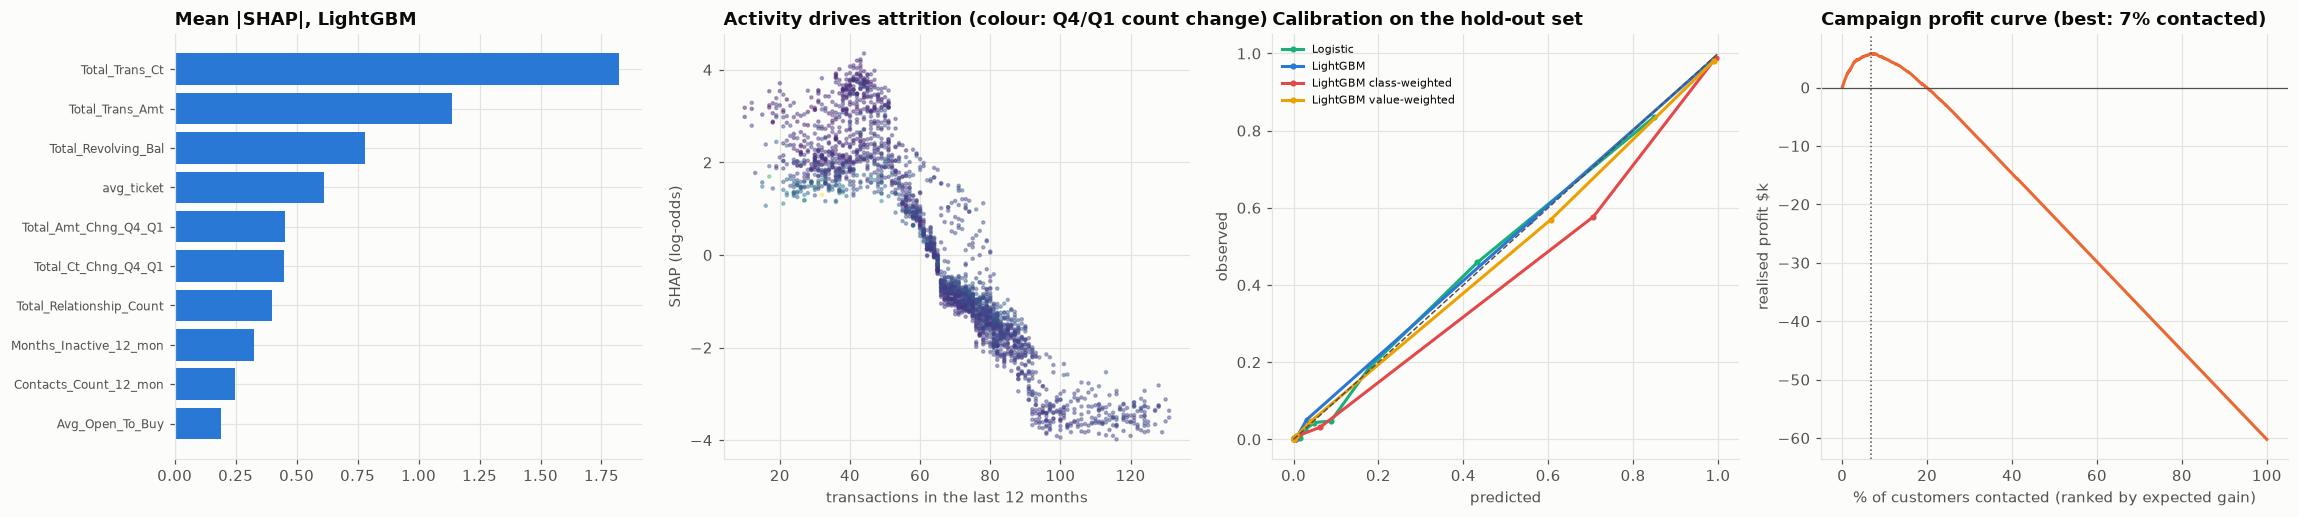

Dashboard saved: outputs/dashboard.html and .png


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
ax = axes[0]
top = shap_imp.head(10).iloc[::-1]
ax.barh(top.index, top.values, color=PALETTE[0]); ax.set_title("Mean |SHAP|, LightGBM"); ax.tick_params(axis="y", labelsize=8)
ax = axes[1]
ax.scatter(hold["Total_Trans_Ct"], contrib["Total_Trans_Ct"], s=4, alpha=0.4, c=hold["Total_Ct_Chng_Q4_Q1"], cmap="viridis")
ax.set_xlabel("transactions in the last 12 months"); ax.set_ylabel("SHAP (log-odds)"); ax.set_title("Activity drives attrition (colour: Q4/Q1 count change)")
ax = axes[2]
for n, col in zip(NAMES, [PALETTE[2], PALETTE[0], PALETTE[7], PALETTE[3]]):
    obs, pred = calibration_curve(y_ho, p_ho[n], n_bins=10, strategy="quantile")
    ax.plot(pred, obs, "o-", ms=3, color=col, label=n)
ax.plot([0, 1], [0, 1], color=INK_2, ls="--", lw=1)
ax.set_title("Calibration on the hold-out set"); ax.set_xlabel("predicted"); ax.set_ylabel("observed"); ax.legend(fontsize=7)
ax = axes[3]
ax.plot(np.arange(1, len(p) + 1) / len(p) * 100, profit_curve / 1e3, color=PALETTE[1])
ax.axvline(best_k / len(p) * 100, color=INK_2, ls=":", lw=1)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xlabel("% of customers contacted (ranked by expected gain)"); ax.set_ylabel("realised profit $k")
ax.set_title(f"Campaign profit curve (best: {best_k / len(p):.0%} contacted)")
plt.tight_layout()
save_fig(fig, "01_drivers_calibration_profit")
plt.show()

seg = hold.assign(p=p, contact=rules["positive expected gain"]).groupby("Card_Category").agg(
    customers=("p", "size"), attrition=("attrited", "mean"), mean_p=("p", "mean"), contacted=("contact", "mean"), value=("value", "median"))
dash = make_subplots(rows=2, cols=3, specs=[[{"type": "indicator"}, {"type": "indicator"}, {"type": "indicator"}],
                                            [{"type": "bar"}, {"type": "xy"}, {"type": "table"}]],
                     subplot_titles=("", "", "", "Top drivers (mean |SHAP|)", "Campaign profit curve", "By card category"),
                     row_heights=[0.25, 0.75], vertical_spacing=0.12)
dash.add_trace(go.Indicator(mode="number", value=y_ho.mean() * 100, number={"suffix": "%", "valueformat": ".1f"},
                            title={"text": "Attrition rate (hold-out)"}), 1, 1)
dash.add_trace(go.Indicator(mode="number", value=perf.loc["LightGBM", "hold-out AUC"], number={"valueformat": ".3f"},
                            title={"text": "LightGBM AUC"}), 1, 2)
dash.add_trace(go.Indicator(mode="number", value=profit_curve[best_k - 1], number={"prefix": "$", "valueformat": ",.0f"},
                            title={"text": f"Best campaign profit ({best_k} contacts)"}), 1, 3)
dash.add_trace(go.Bar(x=top.values, y=top.index, orientation="h", marker_color=PALETTE[0], showlegend=False), 2, 1)
xs = np.arange(1, len(p) + 1) / len(p) * 100
dash.add_trace(go.Scatter(x=xs, y=profit_curve, line=dict(color=PALETTE[1]), showlegend=False), 2, 2)
dash.add_trace(go.Table(header=dict(values=["card", "customers", "attrition %", "mean p %", "contacted %", "median value $"]),
                        cells=dict(values=[seg.index, seg["customers"], (seg["attrition"] * 100).round(1), (seg["mean_p"] * 100).round(1),
                                           (seg["contacted"] * 100).round(1), seg["value"].round(0)])), 2, 3)
dash.update_layout(height=760, width=1500, paper_bgcolor=SURFACE, plot_bgcolor=SURFACE, margin=dict(t=90, l=40, r=30, b=40),
                   title=dict(x=0.01, text="<b>Credit-card attrition · retention campaign</b>"))
save_dashboard(dash, "dashboard")
dash.show()

## 8. Reading the results and limitations

10,127 card customers, 16.1% attrited; 7,595 for development (5-fold cross-validation) and 2,532 held out:

- **Attrition is very predictable here, perhaps too predictable.** LightGBM reaches a hold-out AUC of **0.99** (PR-AUC 0.97); logistic regression reaches 0.94. The drivers are activity: the number of transactions in the last 12 months (median 43 for leavers vs 71 for stayers), total spend, the revolving balance (median **zero** for leavers), and the fall in activity from Q1 to Q4. A validator would ask when these 12-month windows end. If they overlap the months in which customers were already winding down, part of the signal is the attrition itself. A production model must measure behaviour strictly before the prediction date, and its AUC would be lower.
- **Fewer products, more inactivity and more calls to the bank all raise attrition**, the classic signs of a disengaged customer.
- **The unweighted model is the best-calibrated.** Its average predicted probability (15.9%) matches the attrition rate (16.1%) with a Brier score of 0.02. Class weighting raises the average to 17.8% for no gain in ranking. Value weighting keeps the ranking and calibration but does not change the campaign much, because the ranking is already near-perfect.
- **Most leavers are not worth saving.** Leavers mostly carry no revolving balance, so their annual value is a median of $88, against $236 for stayers. With a $30 contact cost and a 30% success rate, saving a $88 customer loses money even when attrition is certain.
- **The campaign should therefore be small.** Contacting every customer with a positive expected gain reaches 188 customers (7.4%) and earns **$5,700** on the hold-out set, $30 per contact. Ranking by expected gain and stopping at the curve's maximum, 171 contacts (6.8%), earns $5,800. The usual rule, "contact everyone with p > 50%", reaches 89% of leavers but earns only $1,500, because most of them are low-value. Contacting everyone loses $60,000. Accuracy and profit point to different campaigns, and the right objective is profit.
- **No obvious gender skew.** 7.0% of women and 7.9% of men would be contacted, close to their attrition rates (16.4% and 15.7%).

**Limitations**

- Customer value is a one-year proxy (revolving interest net of funding and losses, plus interchange), not a lifetime value; offer costs and success rates are assumptions and should come from a randomised test (uplift modelling shows why).
- A single snapshot, with no dates, so there is no out-of-time validation.
- Saving a customer is treated as permanent for the year; in practice some retained customers leave later.

In [9]:
perf.to_csv(OUT_DIR / "model_performance.csv")
shap_imp.rename("mean |SHAP|").to_csv(OUT_DIR / "shap_importance.csv")
camp.to_csv(OUT_DIR / "campaign_rules.csv")
print("Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir())))

Outputs written: 01_drivers_calibration_profit.png, dashboard.html, dashboard.png, campaign_rules.csv, model_performance.csv, shap_importance.csv
